In [1]:
import pandas as pd
import numpy as np
import matplotlib as ptl

# **Step1 : Model prepration**

# **1.1 — Load Data**

In [2]:
featurs_df=pd.read_csv("../data/generated_v2/releases/v2_20261028/account_month_features.csv")
labels_df=pd.read_csv("../data/generated_v2/releases/v2_20261028/evaluation_labels.csv")

# **1.2 — Data Integrity Validation**

In [3]:
featurs_df.duplicated(subset=["account_id", "month"]).sum()

np.int64(0)

In [4]:
labels_df.duplicated(subset=["account_id","month"]).sum()

np.int64(0)

In [5]:
merged=featurs_df.merge(labels_df,on=["account_id","month"], how="outer",indicator=True)

In [6]:
merged["_merge"].value_counts()

_merge
both          6000
left_only        0
right_only       0
Name: count, dtype: int64

In [7]:
merged["_merge"].eq("both").all()

np.True_

# **1.3 — Define Eligible Features**

In [8]:
initial_eligible_features=[
    col for col in featurs_df.columns
    if col not in ["account_id", "month"]
    and not col.endswith("_robust_z_past") 
]
print(initial_eligible_features)
print("Eligible feature count:" , len(initial_eligible_features))

['txn_count', 'unique_counterparties', 'inflow_sum', 'outflow_sum', 'inflow_avg', 'outflow_avg', 'net_flow', 'inflow_outflow_ratio', 'zero_outflow_flag', 'flow_concentration', 'txn_count_change_vs_prev', 'unique_counterparties_change_vs_prev', 'inflow_sum_change_vs_prev', 'outflow_sum_change_vs_prev', 'net_flow_change_vs_prev']
Eligible feature count: 15


# **1.4 — Define Feature Groups**

In [9]:
featurs_df.columns.tolist()

['account_id',
 'month',
 'txn_count',
 'unique_counterparties',
 'inflow_sum',
 'outflow_sum',
 'inflow_avg',
 'outflow_avg',
 'net_flow',
 'inflow_outflow_ratio',
 'zero_outflow_flag',
 'flow_concentration',
 'txn_count_change_vs_prev',
 'txn_count_robust_z_past',
 'unique_counterparties_change_vs_prev',
 'unique_counterparties_robust_z_past',
 'inflow_sum_change_vs_prev',
 'inflow_sum_robust_z_past',
 'outflow_sum_change_vs_prev',
 'outflow_sum_robust_z_past',
 'net_flow_change_vs_prev',
 'net_flow_robust_z_past']

In [10]:
behavioral_features = [
    "txn_count",
    "unique_counterparties",
    "txn_count_change_vs_prev",
    "unique_counterparties_change_vs_prev"
]
fund_flow_extended_features = [
    "inflow_sum",
    "outflow_sum",
    "inflow_avg",
    "outflow_avg",
    "net_flow",
    "inflow_outflow_ratio",
    "zero_outflow_flag",
    "flow_concentration",
    "inflow_sum_change_vs_prev",
    "outflow_sum_change_vs_prev",
    "net_flow_change_vs_prev"
]
fund_flow_core_features = [
    "inflow_sum",
    "outflow_sum",
    "inflow_avg",
    "outflow_avg",
    "net_flow",
    "inflow_outflow_ratio",
    "flow_concentration"
]

combined_core_features = behavioral_features + fund_flow_core_features

feature_groups = {
    "behavioral": behavioral_features,
    "fund_flow_extended": fund_flow_extended_features,
    "fund_flow_core": fund_flow_core_features,
    "combined_core": combined_core_features
}

In [11]:
for group,features  in feature_groups.items():
    print(group, len(features))


behavioral 4
fund_flow_extended 11
fund_flow_core 7
combined_core 11


In [12]:
assert all(
    set(features).issubset(initial_eligible_features)
    for features in feature_groups.values()
)

## **1.5 — Missing Value Analysis**

In [13]:
featurs_df[combined_core_features].isna().sum()

txn_count                                  0
unique_counterparties                      0
txn_count_change_vs_prev                1000
unique_counterparties_change_vs_prev    1000
inflow_sum                                 0
outflow_sum                                0
inflow_avg                                23
outflow_avg                               34
net_flow                                   0
inflow_outflow_ratio                      34
flow_concentration                         0
dtype: int64

In [14]:
featurs_df.groupby("month")[combined_core_features].apply(
    lambda x:x.isna().sum()
)

,txn_count,unique_counterparties,txn_count_change_vs_prev,unique_counterparties_change_vs_prev,inflow_sum,outflow_sum,inflow_avg,outflow_avg,net_flow,inflow_outflow_ratio,flow_concentration
month,,,,,,,,,,,
1,0,0,1000,1000,0,0,0,6,0,6,0
2,0,0,0,0,0,0,2,3,0,3,0
3,0,0,0,0,0,0,5,8,0,8,0
4,0,0,0,0,0,0,4,5,0,5,0
5,0,0,0,0,0,0,4,4,0,4,0
6,0,0,0,0,0,0,8,8,0,8,0


## **Step 1.6 — Temporal Split**

In [15]:
train_df=featurs_df[featurs_df["month"].isin([1,2,3])].copy()
validation_df=featurs_df[featurs_df["month"]==4].copy()
test_df=featurs_df[featurs_df["month"].isin([5,6])].copy()

In [16]:
print("Train",len(train_df))
print("Validation",len(validation_df))
print("Test",len(test_df))

Train 3000
Validation 1000
Test 2000


## **1.7 — Train-only Median Imputation**

**1.7.1 — Calculate training medians**

In [17]:
training_medians = train_df[initial_eligible_features].median()

In [18]:
print(training_medians)
print("Number of medians:", len(training_medians))

txn_count                                  32.000000
unique_counterparties                      22.000000
inflow_sum                              42561.430000
outflow_sum                             47039.395000
inflow_avg                               2599.222174
outflow_avg                              2600.928462
net_flow                                 2105.165000
inflow_outflow_ratio                        1.054297
zero_outflow_flag                           0.000000
flow_concentration                          0.096060
txn_count_change_vs_prev                    0.000000
unique_counterparties_change_vs_prev        0.000000
inflow_sum_change_vs_prev                  -0.013314
outflow_sum_change_vs_prev                 -0.012122
net_flow_change_vs_prev                    -0.000539
dtype: float64
Number of medians: 15


**1.7.2 — Validate the training medians**

In [19]:
training_medians.notna().all()

np.True_

In [20]:
X_train_combined_core=train_df[combined_core_features].fillna(training_medians)
X_validation_combined_core=validation_df[combined_core_features].fillna(training_medians)
X_test_combined_core=test_df[combined_core_features].fillna(training_medians)

In [21]:
print("Train combined core missing: ", X_train_combined_core.isna().sum().sum())
print("Validation combined core missing: ", X_validation_combined_core.isna().sum().sum())
print("Test combined core missing: ", X_test_combined_core.isna().sum().sum())

Train combined core missing:  0
Validation combined core missing:  0
Test combined core missing:  0


**1.7.3 — Validate Model Inputs**
        
          1.The matrices have the expected dimensions.
          2.All values are finite (no NaN, inf, or -inf).
          3.The feature order is identical across Train, Validation, and Test.

**Check matrix shapes**

In [22]:
print("Train :" , X_train_combined_core.shape)
print("Validation :" , X_validation_combined_core.shape)
print("Test :" , X_test_combined_core.shape)

Train : (3000, 11)
Validation : (1000, 11)
Test : (2000, 11)


**Check finite values**

In [23]:
assert np.isfinite(X_train_combined_core.to_numpy()).all()
assert np.isfinite(X_validation_combined_core.to_numpy()).all()
assert np.isfinite(X_test_combined_core.to_numpy()).all()

**Check feature order**

In [24]:
assert X_train_combined_core.columns.equals(
    X_validation_combined_core.columns
)

assert X_train_combined_core.columns.equals(
    X_test_combined_core.columns
)

In [25]:
for name, df in {
    "Train": train_df,
    "Validation": validation_df,
    "Test": test_df
}.items():
    values = df[initial_eligible_features].to_numpy(dtype=float)
    assert not np.isinf(values).any(), f"Infinity found in {name}"

**1.7.4 — Prepare Remaining Feature Groups**

In [26]:
prepared_X = {}

for group_name, features in feature_groups.items():
    prepared_X[group_name] = {
        "train": train_df[features].fillna(training_medians[features]),
        "validation": validation_df[features].fillna(training_medians[features]),
        "test": test_df[features].fillna(training_medians[features])
    }

**Validate all groups**

In [27]:
for group_name, splits in prepared_X.items():
    for split_name, X in splits.items():
        assert np.isfinite(X.to_numpy()).all()
        assert X.columns.tolist() == feature_groups[group_name]

        print(group_name, split_name, X.shape)

behavioral train (3000, 4)
behavioral validation (1000, 4)
behavioral test (2000, 4)
fund_flow_extended train (3000, 11)
fund_flow_extended validation (1000, 11)
fund_flow_extended test (2000, 11)
fund_flow_core train (3000, 7)
fund_flow_core validation (1000, 7)
fund_flow_core test (2000, 7)
combined_core train (3000, 11)
combined_core validation (1000, 11)
combined_core test (2000, 11)


## **1.8 — Verify Label Alignment**

In [28]:
def get_aligned_labels(df, labels_df):
    aligned = df[["account_id", "month"]].merge(
        labels_df[["account_id", "month", "is_injected_anomaly"]],
        on=["account_id", "month"],
        how="left",
        validate="one_to_one",
        sort=False
    )

    assert aligned["is_injected_anomaly"].notna().all()

    return pd.Series(
        aligned["is_injected_anomaly"].astype(int).to_numpy(),
        index=df.index,
        name="is_injected_anomaly"
    )

In [29]:
prepared_y = {
    "train": get_aligned_labels(train_df, labels_df),
    "validation": get_aligned_labels(validation_df, labels_df),
    "test": get_aligned_labels(test_df, labels_df)
}

In [30]:
for split_name in ("train", "validation", "test"):
    X = prepared_X["combined_core"][split_name]
    y = prepared_y[split_name]

    assert X.index.equals(y.index)

    print(split_name, len(y), "anomalies:", y.sum())

train 3000 anomalies: 0
validation 1000 anomalies: 50
test 2000 anomalies: 100


# **Step 2 — Isolation Forest Experiments**

Train four Isolation Forest models using months 1–3.

Select anomaly thresholds using validation month 4.

Evaluate frozen models and thresholds on test months 5–6.

## **Step 2.1 — Setting Isolation Forest**

In [31]:
from sklearn.ensemble import IsolationForest

IF_SETTINGS = {
    "random_state": 42,
    "n_estimators": 200,
    "max_samples": "auto",
    "contamination": "auto"
}

## **Step 2.2 — learning Combined Code**

In [32]:
X_train_combined_core = prepared_X ["combined_core"]["train"]
model_combined_core = IsolationForest(**IF_SETTINGS)
model_combined_core.fit(X_train_combined_core)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


## **Step 2.3 — Evaluate the Trained Model**

In [33]:
print("Number of trees:", len(model_combined_core.estimators_))
print("Samples per tree:", model_combined_core.max_samples_)
print("Number of features:", model_combined_core.n_features_in_)

Number of trees: 200
Samples per tree: 256
Number of features: 11


## **Step 2.4 — Calculate Anomaly Scores**

**2.4.1 — Calculate Validation Anomaly Scores**

**2.4.2 — negative sign**

In [34]:
X_validation_combined_core = prepared_X["combined_core"]["validation"]
validation_scores_combined_model= - model_combined_core.score_samples(X_validation_combined_core)
print(validation_scores_combined_model[:10])

[0.41132962 0.50473143 0.42495204 0.41954754 0.41264165 0.5711046
 0.42247171 0.44770554 0.51436416 0.50158151]


**2.4.3 — Validate the Scores**

In [35]:
print("Number of scores:", len(validation_scores_combined_model))
print("Minimum score:", validation_scores_combined_model.min())
print("Maximum score:", validation_scores_combined_model.max())

assert len(validation_scores_combined_model) == len(X_validation_combined_core)
assert np.isfinite(validation_scores_combined_model).all()

Number of scores: 1000
Minimum score: 0.3549375344867905
Maximum score: 0.674771830895602


## **Step 2.5 — Validation-Based Threshold Selection**

**Step 2.5.1 — Prepare and Verify Validation Labels**

In [36]:
y_validation = prepared_y["validation"]

print("Validation observations:", len(y_validation))
print("Injected anomalies:", y_validation.sum())

assert len(y_validation) == len(validation_scores_combined_model)
assert y_validation.index.equals(X_validation_combined_core.index)

Validation observations: 1000
Injected anomalies: 50


**Step 2.5.2 — Experiment with a Temporary Threshold**

In [37]:
from sklearn.metrics import precision_score, recall_score, f1_score

temporary_threshold = 0.50

y_pred_validation = (
    validation_scores_combined_model >= temporary_threshold
).astype(int)

print("Predicted anomalies:", y_pred_validation.sum())

print("Precision:", precision_score(y_validation, y_pred_validation))
print("Recall:", recall_score(y_validation, y_pred_validation))
print("F1:", f1_score(y_validation, y_pred_validation))

Predicted anomalies: 173
Precision: 0.14450867052023122
Recall: 0.5
F1: 0.2242152466367713


**Step 2.5.3 — Generate Candidate Thresholds**

In [38]:
candidate_thresholds = np.append(
    np.unique(validation_scores_combined_model),
    np.nextafter(validation_scores_combined_model.max(), np.inf)
)

print("Number of candidate thresholds:", len(candidate_thresholds))
print("Minimum threshold:", candidate_thresholds.min())
print("Maximum threshold:", candidate_thresholds.max())

Number of candidate thresholds: 1001
Minimum threshold: 0.3549375344867905
Maximum threshold: 0.6747718308956021


**Step 2.5.4 — Evaluate Every Candidate Threshold**

In [39]:
threshold_results = []

for threshold in candidate_thresholds:

    y_pred = (validation_scores_combined_model >= threshold).astype(int)

    tp = int(((y_validation == 1) & (y_pred == 1)).sum())
    fp = int(((y_validation == 0) & (y_pred == 1)).sum())
    fn = int(((y_validation == 1) & (y_pred == 0)).sum())
    tn = int(((y_validation == 0) & (y_pred == 0)).sum())

    denominator = 2 * tp + fp + fn
    f1 = 2 * tp / denominator if denominator else 0.0

    threshold_results.append({
        "threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "F1": f1,
        "f1_numerator": 2 * tp,
        "f1_denominator": denominator
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.head())

,threshold,TP,FP,FN,TN,F1,f1_numerator,f1_denominator
0,0.354938,50,950,0,0,0.095238,100,1050
1,0.355536,50,949,0,1,0.095329,100,1049
2,0.355610,50,948,0,2,0.095420,100,1048
3,0.356757,49,948,1,2,0.093601,98,1047
4,0.358154,49,947,1,3,0.093690,98,1046


**Step 2.5.5 — Select the Optimal Validation Threshold**

In [40]:
from fractions import Fraction

def threshold_selection_key(row):
    if row["f1_denominator"] > 0:
        exact_f1 = Fraction(
            int(row["f1_numerator"]),
            int(row["f1_denominator"])
        )
    else:
        exact_f1 = Fraction(0)

    return (
        exact_f1,
        -int(row["FP"]),
        float(row["threshold"])
    )

best_threshold_row = max(
    threshold_results,
    key=threshold_selection_key
)

best_threshold_combined_model = float(best_threshold_row["threshold"])

print("Selected threshold:", best_threshold_combined_model)
print("Validation TP:", best_threshold_row["TP"])
print("Validation FP:", best_threshold_row["FP"])
print("Validation FN:", best_threshold_row["FN"])
print("Validation TN:", best_threshold_row["TN"])
print("Validation F1:", best_threshold_row["F1"])

Selected threshold: 0.5203487050781919
Validation TP: 22
Validation FP: 104
Validation FN: 28
Validation TN: 846
Validation F1: 0.25


**Step 2.5.7 — Verify the Selected Threshold**

In [41]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

y_pred_validation_best = (
    validation_scores_combined_model >= best_threshold_combined_model
).astype(int)

print("Confusion matrix:")
print(confusion_matrix(y_validation, y_pred_validation_best))

print("Precision:", precision_score(y_validation, y_pred_validation_best))
print("Recall:", recall_score(y_validation, y_pred_validation_best))
print("F1:", f1_score(y_validation, y_pred_validation_best))

Confusion matrix:
[[846 104]
 [ 28  22]]
Precision: 0.1746031746031746
Recall: 0.44
F1: 0.25


In [42]:
best_threshold_combined_model = 0.5203487050781919

## **Step 2.6 — Evaluate the Combined Core Model on Test**

**Step 2.6.1 — Calculate Test Anomaly Scores**

In [43]:
X_test_combined_core = prepared_X["combined_core"]["test"]

test_scores_combined_model = -model_combined_core.score_samples(
    X_test_combined_core
)

print("Number of test scores:", len(test_scores_combined_model))
print("Minimum score:", test_scores_combined_model.min())
print("Maximum score:", test_scores_combined_model.max())

assert len(test_scores_combined_model) == len(X_test_combined_core)
assert np.isfinite(test_scores_combined_model).all()

Number of test scores: 2000
Minimum score: 0.35480647892273237
Maximum score: 0.6838425415457773


**Step 2.6.2 — Apply the Frozen Threshold**

In [44]:
y_test = prepared_y["test"]

assert len(y_test) == len(test_scores_combined_model)
assert y_test.index.equals(X_test_combined_core.index)

y_pred_test_combined_model = (
    test_scores_combined_model >= best_threshold_combined_model
).astype(int)

print("Test observations:", len(y_test))
print("Actual anomalies:", y_test.sum())
print("Predicted anomalies:", y_pred_test_combined_model.sum())

Test observations: 2000
Actual anomalies: 100
Predicted anomalies: 226


**Step 2.6.3 — Evaluate Test Predictions**

In [45]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

test_confusion_matrix = confusion_matrix(
    y_test,
    y_pred_test_combined_model,
    labels=[0, 1]
)

tn, fp, fn, tp = test_confusion_matrix.ravel()

print("Confusion matrix:")
print(test_confusion_matrix)

print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Negatives:", tn)

print("Precision:", precision_score(y_test, y_pred_test_combined_model))
print("Recall:", recall_score(y_test, y_pred_test_combined_model))
print("F1:", f1_score(y_test, y_pred_test_combined_model))

Confusion matrix:
[[1717  183]
 [  57   43]]
True Positives: 43
False Positives: 183
False Negatives: 57
True Negatives: 1717
Precision: 0.1902654867256637
Recall: 0.43
F1: 0.26380368098159507


**Step 2.6.4 — Calculate Average Precision and PR-AUC**

In [46]:
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    auc
)

test_average_precision = average_precision_score(
    y_test,
    test_scores_combined_model
)

pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_test,
    test_scores_combined_model
)

test_pr_auc = auc(pr_recall, pr_precision)

print("Average Precision:", test_average_precision)
print("PR-AUC (trapezoidal):", test_pr_auc)

Average Precision: 0.22343411571487537
PR-AUC (trapezoidal): 0.21968479973982316


## **Step 2.8 — Behavioral Isolation Forest**

**Step 2.8.1 — Train the Behavioral Model**

In [47]:
X_train_behavioral = prepared_X["behavioral"]["train"]

model_behavioral = IsolationForest(**IF_SETTINGS)

model_behavioral.fit(X_train_behavioral)

print("Training observations:", len(X_train_behavioral))
print("Number of features:", model_behavioral.n_features_in_)
print("Number of trees:", len(model_behavioral.estimators_))
print("Samples per tree:", model_behavioral.max_samples_)

Training observations: 3000
Number of features: 4
Number of trees: 200
Samples per tree: 256


Step 2.8.2 — Calculate Behavioral Validation Scores

In [48]:
X_validation_behavioral = prepared_X["behavioral"]["validation"]

validation_scores_behavioral_model = -model_behavioral.score_samples(
    X_validation_behavioral
)

print("Number of validation scores:", len(validation_scores_behavioral_model))
print("Minimum score:", validation_scores_behavioral_model.min())
print("Maximum score:", validation_scores_behavioral_model.max())

assert len(validation_scores_behavioral_model) == len(X_validation_behavioral)
assert np.isfinite(validation_scores_behavioral_model).all()
assert X_validation_behavioral.index.equals(y_validation.index)

Number of validation scores: 1000
Minimum score: 0.35403848863726994
Maximum score: 0.7707831509674118


**Step 2.8.3 — Select the Behavioral Validation Threshold**

In [49]:
behavioral_candidate_thresholds = np.append(
    np.unique(validation_scores_behavioral_model),
    np.nextafter(validation_scores_behavioral_model.max(), np.inf)
)

behavioral_threshold_results = []

for threshold in behavioral_candidate_thresholds:

    y_pred = (validation_scores_behavioral_model >= threshold).astype(int)

    tp = int(((y_validation == 1) & (y_pred == 1)).sum())
    fp = int(((y_validation == 0) & (y_pred == 1)).sum())
    fn = int(((y_validation == 1) & (y_pred == 0)).sum())
    tn = int(((y_validation == 0) & (y_pred == 0)).sum())

    denominator = 2 * tp + fp + fn

    behavioral_threshold_results.append({
        "threshold": float(threshold),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "F1": 2 * tp / denominator if denominator else 0.0,
        "f1_numerator": 2 * tp,
        "f1_denominator": denominator
    })

best_behavioral_row = max(
    behavioral_threshold_results,
    key=threshold_selection_key
)

best_threshold_behavioral_model = best_behavioral_row["threshold"]

print("Selected threshold:", best_threshold_behavioral_model)
print("Validation TP:", best_behavioral_row["TP"])
print("Validation FP:", best_behavioral_row["FP"])
print("Validation FN:", best_behavioral_row["FN"])
print("Validation TN:", best_behavioral_row["TN"])
print("Validation F1:", best_behavioral_row["F1"])

Selected threshold: 0.5779857912988876
Validation TP: 17
Validation FP: 71
Validation FN: 33
Validation TN: 879
Validation F1: 0.2463768115942029


**Step 2.8.5 — Evaluate Behavioral on Test**

In [50]:
X_test_behavioral = prepared_X["behavioral"]["test"]

test_scores_behavioral_model = -model_behavioral.score_samples(
    X_test_behavioral
)

y_pred_test_behavioral_model = (
    test_scores_behavioral_model >= best_threshold_behavioral_model
).astype(int)

assert len(test_scores_behavioral_model) == len(y_test)
assert X_test_behavioral.index.equals(y_test.index)
assert np.isfinite(test_scores_behavioral_model).all()

print("Test observations:", len(y_test))
print("Actual anomalies:", y_test.sum())
print("Predicted anomalies:", y_pred_test_behavioral_model.sum())

Test observations: 2000
Actual anomalies: 100
Predicted anomalies: 187


**Next — Step 2.8.6: Calculate Test Metrics**

In [51]:
behavioral_cm = confusion_matrix(
    y_test,
    y_pred_test_behavioral_model,
    labels=[0, 1]
)

tn, fp, fn, tp = behavioral_cm.ravel()

behavioral_precision = precision_score(y_test, y_pred_test_behavioral_model)
behavioral_recall = recall_score(y_test, y_pred_test_behavioral_model)
behavioral_f1 = f1_score(y_test, y_pred_test_behavioral_model)

behavioral_ap = average_precision_score(
    y_test, test_scores_behavioral_model
)

pr_precision, pr_recall, _ = precision_recall_curve(
    y_test, test_scores_behavioral_model
)

behavioral_pr_auc = auc(pr_recall, pr_precision)

print("Confusion matrix:")
print(behavioral_cm)

print("TP:", tp, "FP:", fp, "FN:", fn, "TN:", tn)
print("Precision:", behavioral_precision)
print("Recall:", behavioral_recall)
print("F1:", behavioral_f1)
print("Average Precision:", behavioral_ap)
print("PR-AUC (trapezoidal):", behavioral_pr_auc)

Confusion matrix:
[[1746  154]
 [  67   33]]
TP: 33 FP: 154 FN: 67 TN: 1746
Precision: 0.17647058823529413
Recall: 0.33
F1: 0.22996515679442509
Average Precision: 0.1147810650327937
PR-AUC (trapezoidal): 0.1115875122542124


## **Step 2.9 — Fund Flow Core Isolation Forest**

**Step 2.9.1 — Train the Model**

In [52]:
X_train_fund_flow_core = prepared_X["fund_flow_core"]["train"]

model_fund_flow_core = IsolationForest(**IF_SETTINGS)

model_fund_flow_core.fit(X_train_fund_flow_core)

print("Training observations:", len(X_train_fund_flow_core))
print("Number of features:", model_fund_flow_core.n_features_in_)
print("Number of trees:", len(model_fund_flow_core.estimators_))
print("Samples per tree:", model_fund_flow_core.max_samples_)

Training observations: 3000
Number of features: 7
Number of trees: 200
Samples per tree: 256


**Step 2.9.2 — Calculate Validation Scores**

In [53]:
X_validation_fund_flow_core = prepared_X["fund_flow_core"]["validation"]

validation_scores_fund_flow_core_model = -model_fund_flow_core.score_samples(
    X_validation_fund_flow_core
)

print("Number of validation scores:", len(validation_scores_fund_flow_core_model))
print("Minimum score:", validation_scores_fund_flow_core_model.min())
print("Maximum score:", validation_scores_fund_flow_core_model.max())

assert len(validation_scores_fund_flow_core_model) == len(X_validation_fund_flow_core)
assert np.isfinite(validation_scores_fund_flow_core_model).all()
assert X_validation_fund_flow_core.index.equals(y_validation.index)

Number of validation scores: 1000
Minimum score: 0.3583167854916823
Maximum score: 0.7339371837686866


**Step 2.9.3 — Select the Fund Flow Core Threshold**

In [54]:
fund_flow_core_candidate_thresholds = np.append(
    np.unique(validation_scores_fund_flow_core_model),
    np.nextafter(validation_scores_fund_flow_core_model.max(), np.inf)
)

fund_flow_core_threshold_results = []

for threshold in fund_flow_core_candidate_thresholds:

    y_pred = (
        validation_scores_fund_flow_core_model >= threshold
    ).astype(int)

    tp = int(((y_validation == 1) & (y_pred == 1)).sum())
    fp = int(((y_validation == 0) & (y_pred == 1)).sum())
    fn = int(((y_validation == 1) & (y_pred == 0)).sum())
    tn = int(((y_validation == 0) & (y_pred == 0)).sum())

    denominator = 2 * tp + fp + fn

    fund_flow_core_threshold_results.append({
        "threshold": float(threshold),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "F1": 2 * tp / denominator if denominator else 0.0,
        "f1_numerator": 2 * tp,
        "f1_denominator": denominator
    })

best_fund_flow_core_row = max(
    fund_flow_core_threshold_results,
    key=threshold_selection_key
)

best_threshold_fund_flow_core_model = best_fund_flow_core_row["threshold"]

print("Selected threshold:", best_threshold_fund_flow_core_model)
print("Validation TP:", best_fund_flow_core_row["TP"])
print("Validation FP:", best_fund_flow_core_row["FP"])
print("Validation FN:", best_fund_flow_core_row["FN"])
print("Validation TN:", best_fund_flow_core_row["TN"])
print("Validation F1:", best_fund_flow_core_row["F1"])

Selected threshold: 0.6044682445965254
Validation TP: 11
Validation FP: 22
Validation FN: 39
Validation TN: 928
Validation F1: 0.26506024096385544


**Step 2.9.4 — Evaluate Fund Flow Core on Test**

In [55]:
X_test_fund_flow_core = prepared_X["fund_flow_core"]["test"]

test_scores_fund_flow_core_model = -model_fund_flow_core.score_samples(
    X_test_fund_flow_core
)

y_pred_test_fund_flow_core_model = (
    test_scores_fund_flow_core_model >= best_threshold_fund_flow_core_model
).astype(int)

assert len(test_scores_fund_flow_core_model) == len(y_test)
assert X_test_fund_flow_core.index.equals(y_test.index)
assert np.isfinite(test_scores_fund_flow_core_model).all()

print("Test observations:", len(y_test))
print("Actual anomalies:", y_test.sum())
print("Predicted anomalies:", y_pred_test_fund_flow_core_model.sum())

Test observations: 2000
Actual anomalies: 100
Predicted anomalies: 58


**Step 2.9.5 — Calculate Test Metrics**

In [56]:
fund_flow_core_cm = confusion_matrix(
    y_test,
    y_pred_test_fund_flow_core_model,
    labels=[0, 1]
)

tn, fp, fn, tp = fund_flow_core_cm.ravel()

fund_flow_core_precision = precision_score(
    y_test, y_pred_test_fund_flow_core_model
)

fund_flow_core_recall = recall_score(
    y_test, y_pred_test_fund_flow_core_model
)

fund_flow_core_f1 = f1_score(
    y_test, y_pred_test_fund_flow_core_model
)

fund_flow_core_ap = average_precision_score(
    y_test, test_scores_fund_flow_core_model
)

pr_precision, pr_recall, _ = precision_recall_curve(
    y_test, test_scores_fund_flow_core_model
)

fund_flow_core_pr_auc = auc(pr_recall, pr_precision)

print("Confusion matrix:")
print(fund_flow_core_cm)

print("TP:", tp, "FP:", fp, "FN:", fn, "TN:", tn)
print("Precision:", fund_flow_core_precision)
print("Recall:", fund_flow_core_recall)
print("F1:", fund_flow_core_f1)
print("Average Precision:", fund_flow_core_ap)
print("PR-AUC (trapezoidal):", fund_flow_core_pr_auc)

Confusion matrix:
[[1863   37]
 [  79   21]]
TP: 21 FP: 37 FN: 79 TN: 1863
Precision: 0.3620689655172414
Recall: 0.21
F1: 0.26582278481012656
Average Precision: 0.204531608716589
PR-AUC (trapezoidal): 0.20191856938307082


## **Step 2.10 — Fund Flow Extended Isolation Forest**

**Step 2.10.1 — Train Fund Flow Extended**

In [57]:
X_train_fund_flow_extended = prepared_X["fund_flow_extended"]["train"]

model_fund_flow_extended = IsolationForest(**IF_SETTINGS)

model_fund_flow_extended.fit(X_train_fund_flow_extended)

print("Training observations:", len(X_train_fund_flow_extended))
print("Number of features:", model_fund_flow_extended.n_features_in_)
print("Number of trees:", len(model_fund_flow_extended.estimators_))
print("Samples per tree:", model_fund_flow_extended.max_samples_)

Training observations: 3000
Number of features: 11
Number of trees: 200
Samples per tree: 256


**Step 2.10.2 — Calculate Validation Scores**

In [58]:
X_validation_fund_flow_extended = prepared_X["fund_flow_extended"]["validation"]

validation_scores_fund_flow_extended_model = (
    -model_fund_flow_extended.score_samples(
        X_validation_fund_flow_extended
    )
)

print("Number of validation scores:", len(validation_scores_fund_flow_extended_model))
print("Minimum score:", validation_scores_fund_flow_extended_model.min())
print("Maximum score:", validation_scores_fund_flow_extended_model.max())

assert len(validation_scores_fund_flow_extended_model) == len(X_validation_fund_flow_extended)
assert np.isfinite(validation_scores_fund_flow_extended_model).all()
assert X_validation_fund_flow_extended.index.equals(y_validation.index)

Number of validation scores: 1000
Minimum score: 0.3416876168892523
Maximum score: 0.7228988416407097


**Step 2.10.3 — Select the Validation Threshold**

In [59]:
fund_flow_extended_candidate_thresholds = np.append(
    np.unique(validation_scores_fund_flow_extended_model),
    np.nextafter(validation_scores_fund_flow_extended_model.max(), np.inf)
)

fund_flow_extended_threshold_results = []

for threshold in fund_flow_extended_candidate_thresholds:

    y_pred = (
        validation_scores_fund_flow_extended_model >= threshold
    ).astype(int)

    tp = int(((y_validation == 1) & (y_pred == 1)).sum())
    fp = int(((y_validation == 0) & (y_pred == 1)).sum())
    fn = int(((y_validation == 1) & (y_pred == 0)).sum())
    tn = int(((y_validation == 0) & (y_pred == 0)).sum())

    denominator = 2 * tp + fp + fn

    fund_flow_extended_threshold_results.append({
        "threshold": float(threshold),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "F1": 2 * tp / denominator if denominator else 0.0,
        "f1_numerator": 2 * tp,
        "f1_denominator": denominator
    })

best_fund_flow_extended_row = max(
    fund_flow_extended_threshold_results,
    key=threshold_selection_key
)

best_threshold_fund_flow_extended_model = (
    best_fund_flow_extended_row["threshold"]
)

print("Selected threshold:", best_threshold_fund_flow_extended_model)
print("Validation TP:", best_fund_flow_extended_row["TP"])
print("Validation FP:", best_fund_flow_extended_row["FP"])
print("Validation FN:", best_fund_flow_extended_row["FN"])
print("Validation TN:", best_fund_flow_extended_row["TN"])
print("Validation F1:", best_fund_flow_extended_row["F1"])

Selected threshold: 0.5350066982185415
Validation TP: 17
Validation FP: 47
Validation FN: 33
Validation TN: 903
Validation F1: 0.2982456140350877


**Step 2.10.4 — Evaluate Fund Flow Extended on Test**

In [60]:
X_test_fund_flow_extended = prepared_X["fund_flow_extended"]["test"]

test_scores_fund_flow_extended_model = (
    -model_fund_flow_extended.score_samples(
        X_test_fund_flow_extended
    )
)

y_pred_test_fund_flow_extended_model = (
    test_scores_fund_flow_extended_model
    >= best_threshold_fund_flow_extended_model
).astype(int)

assert len(test_scores_fund_flow_extended_model) == len(y_test)
assert X_test_fund_flow_extended.index.equals(y_test.index)
assert np.isfinite(test_scores_fund_flow_extended_model).all()

print("Test observations:", len(y_test))
print("Actual anomalies:", y_test.sum())
print("Predicted anomalies:", y_pred_test_fund_flow_extended_model.sum())

Test observations: 2000
Actual anomalies: 100
Predicted anomalies: 106


**Step 2.10.5 — Calculate Test Metrics**

In [61]:
fund_flow_extended_cm = confusion_matrix(
    y_test,
    y_pred_test_fund_flow_extended_model,
    labels=[0, 1]
)

tn, fp, fn, tp = fund_flow_extended_cm.ravel()

fund_flow_extended_precision = precision_score(
    y_test, y_pred_test_fund_flow_extended_model
)

fund_flow_extended_recall = recall_score(
    y_test, y_pred_test_fund_flow_extended_model
)

fund_flow_extended_f1 = f1_score(
    y_test, y_pred_test_fund_flow_extended_model
)

fund_flow_extended_ap = average_precision_score(
    y_test, test_scores_fund_flow_extended_model
)

pr_precision, pr_recall, _ = precision_recall_curve(
    y_test, test_scores_fund_flow_extended_model
)

fund_flow_extended_pr_auc = auc(pr_recall, pr_precision)

print("Confusion matrix:")
print(fund_flow_extended_cm)

print("TP:", tp, "FP:", fp, "FN:", fn, "TN:", tn)
print("Precision:", fund_flow_extended_precision)
print("Recall:", fund_flow_extended_recall)
print("F1:", fund_flow_extended_f1)
print("Average Precision:", fund_flow_extended_ap)
print("PR-AUC (trapezoidal):", fund_flow_extended_pr_auc)

Confusion matrix:
[[1820   80]
 [  74   26]]
TP: 26 FP: 80 FN: 74 TN: 1820
Precision: 0.24528301886792453
Recall: 0.26
F1: 0.2524271844660194
Average Precision: 0.24970490806051965
PR-AUC (trapezoidal): 0.24747758118168248


## **Step 2.13 — Save the Four-Model Baseline**

In [62]:
baseline_results = pd.DataFrame([
    {
        "model": "behavioral",
        "features": 4,
        "threshold": best_threshold_behavioral_model,
        "precision": behavioral_precision,
        "recall": behavioral_recall,
        "F1": behavioral_f1,
        "average_precision": behavioral_ap,
        "PR_AUC": behavioral_pr_auc
    },
    {
        "model": "fund_flow_core",
        "features": 7,
        "threshold": best_threshold_fund_flow_core_model,
        "precision": fund_flow_core_precision,
        "recall": fund_flow_core_recall,
        "F1": fund_flow_core_f1,
        "average_precision": fund_flow_core_ap,
        "PR_AUC": fund_flow_core_pr_auc
    },
    {
        "model": "combined_core",
        "features": 11,
        "threshold": best_threshold_combined_model,
        "precision": precision_score(y_test, y_pred_test_combined_model),
        "recall": recall_score(y_test, y_pred_test_combined_model),
        "F1": f1_score(y_test, y_pred_test_combined_model),
        "average_precision": test_average_precision,
        "PR_AUC": test_pr_auc
    },
    {
        "model": "fund_flow_extended",
        "features": 11,
        "threshold": best_threshold_fund_flow_extended_model,
        "precision": fund_flow_extended_precision,
        "recall": fund_flow_extended_recall,
        "F1": fund_flow_extended_f1,
        "average_precision": fund_flow_extended_ap,
        "PR_AUC": fund_flow_extended_pr_auc
    }
])

display(baseline_results)

,model,features,threshold,precision,recall,F1,average_precision,PR_AUC
0,behavioral,4,0.577986,0.176471,0.33,0.229965,0.114781,0.111588
1,fund_flow_core,7,0.604468,0.362069,0.21,0.265823,0.204532,0.201919
2,combined_core,11,0.520349,0.190265,0.43,0.263804,0.223434,0.219685
3,fund_flow_extended,11,0.535007,0.245283,0.26,0.252427,0.249705,0.247478


**Export the results**

In [63]:
baseline_results.to_csv(
    "../results/isolation_forest_v2_baseline.csv",
    index=False,
    float_format="%.15g"
)

print("Baseline results saved successfully.")

Baseline results saved successfully.


# **Step 3 — Threshold Comparison**

## **Step 3.1 — Calculate Training Q95 Thresholds**

In [64]:
# Step 3.1 — Training Q95 thresholds (Method A)

step3_models = {
    "behavioral": model_behavioral,
    "fund_flow_core": model_fund_flow_core,
    "combined_core": model_combined_core,
    "fund_flow_extended": model_fund_flow_extended
}

step3_training_scores = {}
step3_threshold_A = {}

for model_name, model in step3_models.items():

    X_train = prepared_X[model_name]["train"]

    # Higher score means more anomalous
    training_scores = -model.score_samples(X_train)

    # Method A: 95th percentile of training scores
    threshold = np.quantile(
        training_scores,
        0.95,
        method="linear"
    )

    step3_training_scores[model_name] = training_scores
    step3_threshold_A[model_name] = float(threshold)

    print(
        f"{model_name}: "
        f"Q95 threshold = {threshold:.15f}"
    )

behavioral: Q95 threshold = 0.586160715843841
fund_flow_core: Q95 threshold = 0.564993627956797
combined_core: Q95 threshold = 0.538858693051954
fund_flow_extended: Q95 threshold = 0.519253370983104


## **Step 3.2 — Compare Method A and Method B on Test**

In [65]:
# Step 3.2 — Compare Training Q95 vs Validation F1

step3_threshold_B = {
    "behavioral": best_threshold_behavioral_model,
    "fund_flow_core": best_threshold_fund_flow_core_model,
    "combined_core": best_threshold_combined_model,
    "fund_flow_extended": best_threshold_fund_flow_extended_model
}

step3_results = []

for model_name, model in step3_models.items():

    X_test = prepared_X[model_name]["test"]

    # Calculate test scores
    test_scores = -model.score_samples(X_test)

    assert X_test.index.equals(y_test.index)

    for method, threshold in [
        ("A_Train_Q95", step3_threshold_A[model_name]),
        ("B_Validation_F1", step3_threshold_B[model_name])
    ]:

        y_pred = (test_scores >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test, y_pred, labels=[0, 1]
        ).ravel()

        step3_results.append({
            "model": model_name,
            "method": method,
            "threshold": threshold,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn,
            "alerts": int(y_pred.sum()),
            "precision": precision_score(y_test, y_pred),
            "recall": recall_score(y_test, y_pred),
            "F1": f1_score(y_test, y_pred)
        })

step3_comparison = pd.DataFrame(step3_results)

display(
    step3_comparison.round(4)
)

,model,method,threshold,TP,FP,FN,TN,alerts,precision,recall,F1
0,behavioral,A_Train_Q95,0.5862,31,134,69,1766,165,0.1879,0.31,0.2340
1,behavioral,B_Validation_F1,0.5780,33,154,67,1746,187,0.1765,0.33,0.2300
2,fund_flow_core,A_Train_Q95,0.5650,26,84,74,1816,110,0.2364,0.26,0.2476
3,fund_flow_core,B_Validation_F1,0.6045,21,37,79,1863,58,0.3621,0.21,0.2658
4,combined_core,A_Train_Q95,0.5389,33,123,67,1777,156,0.2115,0.33,0.2578
5,combined_core,B_Validation_F1,0.5203,43,183,57,1717,226,0.1903,0.43,0.2638
6,fund_flow_extended,A_Train_Q95,0.5193,32,123,68,1777,155,0.2065,0.32,0.2510
7,fund_flow_extended,B_Validation_F1,0.5350,26,80,74,1820,106,0.2453,0.26,0.2524


# **Step 4 — Diagnostic Analysis**

## **Step 4.1 — Alert Overlap Analysis**

In [66]:
# Step 4.1 — Alert Overlap Analysis

import numpy as np
import pandas as pd

# Behavioral model scores
behavioral_scores = -model_behavioral.score_samples(
    prepared_X["behavioral"]["test"]
)

# Fund Flow Core model scores
fund_flow_scores = -model_fund_flow_core.score_samples(
    prepared_X["fund_flow_core"]["test"]
)

# Predictions using Method B thresholds
behavioral_alerts = (
    behavioral_scores >= step3_threshold_B["behavioral"]
)

fund_flow_alerts = (
    fund_flow_scores >= step3_threshold_B["fund_flow_core"]
)

# Ensure the two test sets are aligned
assert prepared_X["behavioral"]["test"].index.equals(
    prepared_X["fund_flow_core"]["test"].index
)

assert prepared_X["behavioral"]["test"].index.equals(
    y_test.index
)

# Classify alert overlap
overlap_category = np.select(
    [
        behavioral_alerts & fund_flow_alerts,
        behavioral_alerts & ~fund_flow_alerts,
        ~behavioral_alerts & fund_flow_alerts
    ],
    [
        "Both",
        "Behavioral Only",
        "Fund Flow Only"
    ],
    default="Neither"
)

overlap_results = pd.DataFrame({
    "category": overlap_category,
    "is_anomaly": y_test.to_numpy()
})

# Count all accounts by overlap category
overlap_summary = (
    overlap_results
    .groupby("category")
    .agg(
        total=("is_anomaly", "size"),
        actual_anomalies=("is_anomaly", "sum")
    )
    .reset_index()
)

overlap_summary["normal_accounts"] = (
    overlap_summary["total"]
    - overlap_summary["actual_anomalies"]
)

display(overlap_summary)

,category,total,actual_anomalies,normal_accounts
0,Behavioral Only,175,30,145
1,Both,12,3,9
2,Fund Flow Only,46,18,28
3,Neither,1767,49,1718


## **Step 4.2 — Scenario-Level Analysis**

In [67]:

# Step 4.2 — Align scenario labels with Test data

test_index = prepared_X["behavioral"]["test"].index

# Use original row indices
assert test_index.isin(labels_df.index).all()

test_labels = labels_df.loc[test_index].copy()

# Verify alignment
assert len(test_labels) == len(y_test)

assert np.array_equal(
    test_labels["is_injected_anomaly"].to_numpy(),
    y_test.to_numpy()
)

# Add scenario information
overlap_results["scenario"] = test_labels["scenario"].to_numpy()

# Focus only on actual injected anomalies
anomaly_overlap = overlap_results[
    overlap_results["is_anomaly"] == 1
].copy()

# Count detections by scenario and overlap category
scenario_overlap = pd.crosstab(
    anomaly_overlap["scenario"],
    anomaly_overlap["category"]
)

scenario_overlap = scenario_overlap.reindex(
    columns=[
        "Behavioral Only",
        "Both",
        "Fund Flow Only",
        "Neither"
    ],
    fill_value=0
)

# Total anomalies and detection rates
scenario_overlap["total_anomalies"] = (
    scenario_overlap[
        ["Behavioral Only", "Both", "Fund Flow Only", "Neither"]
    ].sum(axis=1)
)

scenario_overlap["behavioral_recall"] = (
    scenario_overlap["Behavioral Only"] + scenario_overlap["Both"]
) / scenario_overlap["total_anomalies"]

scenario_overlap["fund_flow_recall"] = (
    scenario_overlap["Fund Flow Only"] + scenario_overlap["Both"]
) / scenario_overlap["total_anomalies"]

scenario_overlap["union_recall"] = (
    scenario_overlap["Behavioral Only"]
    + scenario_overlap["Both"]
    + scenario_overlap["Fund Flow Only"]
) / scenario_overlap["total_anomalies"]

display(scenario_overlap.round(3))


category,Behavioral Only,Both,Fund Flow Only,Neither,total_anomalies,behavioral_recall,fund_flow_recall,union_recall
scenario,,,,,,,,
S1_transaction_count_spike,12,2,1,5,20,0.70,0.15,0.75
S2_transaction_amount_shift,0,0,15,5,20,0.00,0.75,0.75
S3_inflow_outflow_shift,2,0,1,17,20,0.10,0.05,0.15
S4_counterparty_diversity_spike,12,0,0,8,20,0.60,0.00,0.60
S5_combined_moderate_shift,4,1,1,14,20,0.25,0.10,0.30


# **Step 4.3 — False Positive Analysis**

In [68]:

# Step 4.3 — Compare alert strategies on Test

from sklearn.metrics import precision_score, recall_score, f1_score

combined_scores = -model_combined_core.score_samples(
    prepared_X["combined_core"]["test"]
)

assert prepared_X["combined_core"]["test"].index.equals(
    y_test.index
)

combined_alerts = (
    combined_scores >= step3_threshold_B["combined_core"]
)

strategies = {
    "Behavioral": behavioral_alerts,
    "Fund Flow Core": fund_flow_alerts,
    "Union (OR)": behavioral_alerts | fund_flow_alerts,
    "Combined Core": combined_alerts
}

comparison_rows = []

for name, alerts in strategies.items():
    predictions = np.asarray(alerts, dtype=int)

    tp = int(((predictions == 1) & (y_test.to_numpy() == 1)).sum())
    fp = int(((predictions == 1) & (y_test.to_numpy() == 0)).sum())

    comparison_rows.append({
        "strategy": name,
        "TP": tp,
        "FP": fp,
        "alerts": int(predictions.sum()),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions)
    })

strategy_comparison = pd.DataFrame(comparison_rows)

display(strategy_comparison.round(4))


,strategy,TP,FP,alerts,precision,recall,F1
0,Behavioral,33,154,187,0.1765,0.33,0.2300
1,Fund Flow Core,21,37,58,0.3621,0.21,0.2658
2,Union (OR),51,182,233,0.2189,0.51,0.3063
3,Combined Core,43,183,226,0.1903,0.43,0.2638


# **Step 5 — Score Fusion**

## **Step 5.1 — Examine Score Distributions**

In [69]:

# Step 5.1 — Examine anomaly score distributions

import numpy as np
import pandas as pd

fusion_models = {
    "behavioral": model_behavioral,
    "fund_flow_core": model_fund_flow_core
}

fusion_scores = {}

for model_name, model in fusion_models.items():

    fusion_scores[model_name] = {}

    for split in ["train", "validation", "test"]:

        X = prepared_X[model_name][split]

        # Higher score = more anomalous
        scores = -model.score_samples(X)

        fusion_scores[model_name][split] = scores

# Summary based on Train scores only
score_summary = []

for model_name in fusion_models:

    scores = fusion_scores[model_name]["train"]

    score_summary.append({
        "model": model_name,
        "min": np.min(scores),
        "mean": np.mean(scores),
        "std": np.std(scores),
        "median": np.median(scores),
        "max": np.max(scores),
        "q95": np.quantile(scores, 0.95)
    })

score_summary_df = pd.DataFrame(score_summary)

display(score_summary_df.round(4))


,model,min,mean,std,median,max,q95
0,behavioral,0.3540,0.4374,0.0706,0.4208,0.7692,0.5862
1,fund_flow_core,0.3566,0.4365,0.0657,0.4151,0.7277,0.5650


## **Step 5.2 — Check Score Correlation**

In [70]:

# Step 5.2 — Correlation between anomaly scores

# Verify account-month alignment
for split in ["train", "validation", "test"]:
    assert prepared_X["behavioral"][split].index.equals(
        prepared_X["fund_flow_core"][split].index
    )

correlation_results = []

for split in ["train", "validation", "test"]:

    behavioral = fusion_scores["behavioral"][split]
    fund_flow = fusion_scores["fund_flow_core"][split]

    correlation = np.corrcoef(
        behavioral,
        fund_flow
    )[0, 1]

    correlation_results.append({
        "split": split,
        "pearson_correlation": correlation
    })

correlation_df = pd.DataFrame(correlation_results)

display(correlation_df.round(4))


,split,pearson_correlation
0,train,0.1217
1,validation,0.1940
2,test,0.1548


## **Step 5.3 — Normalize Scores Using Train Statistics**

In [71]:

# Step 5.3 — Train-based Z-score normalization

fusion_normalized = {}
fusion_scalers = {}

for model_name in fusion_models:

    train_scores = fusion_scores[model_name]["train"]

    train_mean = np.mean(train_scores)
    train_std = np.std(train_scores)

    assert train_std > 0

    fusion_scalers[model_name] = {
        "mean": train_mean,
        "std": train_std
    }

    fusion_normalized[model_name] = {}

    for split in ["train", "validation", "test"]:

        scores = fusion_scores[model_name][split]

        normalized_scores = (
            scores - train_mean
        ) / train_std

        fusion_normalized[model_name][split] = normalized_scores

# Verify normalization on Train
for model_name in fusion_models:

    z = fusion_normalized[model_name]["train"]

    print(
        model_name,
        "mean =", round(np.mean(z), 6),
        "std =", round(np.std(z), 6)
    )


behavioral mean = 0.0 std = 1.0
fund_flow_core mean = -0.0 std = 1.0


## **Step 5.4 — Create Mean Fusion and Max Fusion Scores**

In [72]:

# Step 5.4 — Mean Fusion and Max Fusion

fusion_methods = {
    "mean_fusion": {},
    "max_fusion": {}
}

for split in ["train", "validation", "test"]:

    b = fusion_normalized["behavioral"][split]
    f = fusion_normalized["fund_flow_core"][split]

    fusion_methods["mean_fusion"][split] = (b + f) / 2

    fusion_methods["max_fusion"][split] = np.maximum(b, f)

# Display score ranges on Validation
for method_name, split_scores in fusion_methods.items():

    scores = split_scores["validation"]

    print(
        method_name,
        "min =", round(np.min(scores), 4),
        "max =", round(np.max(scores), 4),
        "mean =", round(np.mean(scores), 4)
    )


mean_fusion min = -1.0623 max = 3.3723 mean = 0.2077
max_fusion min = -1.0388 max = 4.7201 mean = 0.7555


## **Step 5.5 — Select Fusion Thresholds Using Validation**

In [73]:

# Step 5.5 — Select Fusion thresholds on Validation

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Validation labels
assert prepared_X["behavioral"]["validation"].index.equals(
    y_validation.index
)

assert prepared_X["fund_flow_core"]["validation"].index.equals(
    y_validation.index
)

y_val = y_validation.to_numpy()

fusion_thresholds = {}
fusion_validation_results = []

for method_name, split_scores in fusion_methods.items():

    scores = split_scores["validation"]

    assert len(scores) == len(y_val)

    # Candidate thresholds: unique observed scores
    candidate_thresholds = np.unique(scores)

    best_result = None

    for threshold in candidate_thresholds:

        predictions = (scores >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        precision = precision_score(
            y_val, predictions, zero_division=0
        )
        recall = recall_score(
            y_val, predictions, zero_division=0
        )
        f1 = f1_score(
            y_val, predictions, zero_division=0
        )

        candidate = {
            "method": method_name,
            "threshold": float(threshold),
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "TN": int(tn),
            "precision": precision,
            "recall": recall,
            "F1": f1
        }

        if best_result is None or (
            candidate["F1"],
            -candidate["FP"],
            candidate["threshold"]
        ) > (
            best_result["F1"],
            -best_result["FP"],
            best_result["threshold"]
        ):
            best_result = candidate

    fusion_thresholds[method_name] = best_result["threshold"]
    fusion_validation_results.append(best_result)

fusion_validation_df = pd.DataFrame(
    fusion_validation_results
)

display(fusion_validation_df.round(4))


,method,threshold,TP,FP,FN,TN,precision,recall,F1
0,mean_fusion,0.9889,26,135,24,815,0.1615,0.52,0.2464
1,max_fusion,2.4018,22,70,28,880,0.2391,0.44,0.3099


## **Step 5.6 — Evaluate Fusion on Test**

In [74]:

# Step 5.6 — Evaluate Fusion methods on Test

from sklearn.metrics import average_precision_score

assert prepared_X["behavioral"]["test"].index.equals(
    prepared_X["fund_flow_core"]["test"].index
)

assert prepared_X["behavioral"]["test"].index.equals(
    y_test.index
)

y_true = y_test.to_numpy()

fusion_test_results = []

for method_name, split_scores in fusion_methods.items():

    scores = split_scores["test"]
    threshold = fusion_thresholds[method_name]

    predictions = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    fusion_test_results.append({
        "strategy": method_name,
        "threshold": threshold,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "alerts": int(predictions.sum()),
        "precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "AP": average_precision_score(y_true, scores)
    })

fusion_test_df = pd.DataFrame(fusion_test_results)

display(fusion_test_df.round(4))


,strategy,threshold,TP,FP,FN,TN,alerts,precision,recall,F1,AP
0,mean_fusion,0.9889,52,259,48,1641,311,0.1672,0.52,0.2530,0.1504
1,max_fusion,2.4018,43,128,57,1772,171,0.2515,0.43,0.3173,0.1894


# **Step 6 — Explainability**

## **Step 6.1 — Designing Alert Explainability**
   **1. Model-level evidence**
   
   **2. Feature-level evidence**

## **Step 6.2 — Selecting a real alert from the test**

In [75]:

# Step 6.2 — Select an anomalous alert for explanation

import numpy as np
import pandas as pd

max_scores = fusion_methods["max_fusion"]["test"]
max_threshold = fusion_thresholds["max_fusion"]

max_alerts = max_scores >= max_threshold

test_index = prepared_X["behavioral"]["test"].index

assert test_index.equals(y_test.index)

# Find correctly detected injected anomalies
true_positive_positions = np.flatnonzero(
    max_alerts & (y_test.to_numpy() == 1)
)

assert len(true_positive_positions) > 0

# Select the highest-scoring true positive
selected_position = true_positive_positions[
    np.argmax(max_scores[true_positive_positions])
]

selected_index = test_index[selected_position]

print("Selected row index:", selected_index)
print("Max Fusion score:", round(max_scores[selected_position], 4))
print("Fusion threshold:", round(max_threshold, 4))

print(
    "Behavioral normalized score:",
    round(
        fusion_normalized["behavioral"]["test"][selected_position],
        4
    )
)

print(
    "Fund Flow normalized score:",
    round(
        fusion_normalized["fund_flow_core"]["test"][selected_position],
        4
    )
)


Selected row index: 5026
Max Fusion score: 4.5141
Fusion threshold: 2.4018
Behavioral normalized score: 0.0047
Fund Flow normalized score: 4.5141


## **Step 6.3 — Feature-level evidence using robust deviations**

**1. Population Level**


In [76]:

# Use original model features, before imputation if available
feature_groups = {
    "behavioral": prepared_X["behavioral"],
    "fund_flow_core": prepared_X["fund_flow_core"]
}

explanation_rows = []

for group_name, splits in feature_groups.items():

    train_df = splits["train"]
    test_df = splits["test"]

    selected_row = test_df.loc[selected_index]

    for feature in train_df.columns:

        train_values = pd.to_numeric(
            train_df[feature], errors="coerce"
        ).dropna()

        if train_values.empty:
            continue

        median = train_values.median()
        mad = np.median(np.abs(train_values - median))

        value = selected_row[feature]

        if pd.isna(value):
            continue

        # Avoid division by zero for constant features
        if mad == 0:
            robust_z = np.nan
        else:
            robust_z = (value - median) / (1.4826 * mad)

        explanation_rows.append({
            "group": group_name,
            "feature": feature,
            "value": value,
            "train_median": median,
            "robust_z": robust_z,
            "absolute_deviation": abs(robust_z)
                if pd.notna(robust_z) else np.nan
        })

feature_evidence = pd.DataFrame(explanation_rows)

feature_evidence = feature_evidence.sort_values(
    "absolute_deviation",
    ascending=False,
    na_position="last"
)

display(feature_evidence.head(10).round(3))


,group,feature,value,train_median,robust_z,absolute_deviation
7,fund_flow_core,outflow_avg,20271.009,2600.928,24.433,24.433
6,fund_flow_core,inflow_avg,21194.903,2599.222,23.610,23.610
4,fund_flow_core,inflow_sum,699431.790,42561.430,18.542,18.542
8,fund_flow_core,net_flow,557534.730,2105.165,17.573,17.573
9,fund_flow_core,inflow_outflow_ratio,4.929,1.054,4.642,4.642
5,fund_flow_core,outflow_sum,141897.060,47039.395,3.592,3.592
3,behavioral,unique_counterparties_change_vs_prev,0.190,0.000,2.313,2.313
2,behavioral,txn_count_change_vs_prev,0.212,0.000,1.746,1.746
0,behavioral,txn_count,40.000,32.000,0.771,0.771
1,behavioral,unique_counterparties,25.000,22.000,0.506,0.506


## **Step 6.4 — Reviewing Account History and the Injected Scenario**
**2. Account-history-level**

In [77]:

# Step 6.4 — Inspect selected account history

selected_label = labels_df.loc[selected_index]

account_id = selected_label["account_id"]
month = selected_label["month"]
scenario = selected_label["scenario"]

print("Account ID:", account_id)
print("Month:", month)
print("Injected scenario:", scenario)
print("Injected anomaly:", selected_label["is_injected_anomaly"])

history_features = [
    "txn_count",
    "inflow_sum",
    "outflow_sum",
    "inflow_avg",
    "outflow_avg",
    "net_flow",
    "inflow_outflow_ratio",
    "unique_counterparties"
]

account_history = featurs_df.loc[
    featurs_df["account_id"] == account_id,
    ["month"] + history_features
].sort_values("month")

display(account_history.round(2))


Account ID: ACC00838
Month: 5
Injected scenario: S2_transaction_amount_shift
Injected anomaly: 1


,month,txn_count,inflow_sum,outflow_sum,inflow_avg,outflow_avg,net_flow,inflow_outflow_ratio,unique_counterparties
5022,1,30,129086.02,36970.22,5867.55,4621.28,92115.80,3.49,23
5023,2,36,182989.52,32820.53,6309.98,4688.65,150168.99,5.58,26
5024,3,33,154080.03,40698.85,6699.13,4069.88,113381.18,3.79,19
5025,4,33,178861.13,25822.62,6624.49,4303.77,153038.51,6.93,21
5026,5,40,699431.79,141897.06,21194.90,20271.01,557534.73,4.93,25
5027,6,35,166947.74,14619.24,5385.41,3654.81,152328.50,11.42,25


## **Step 6.5 — Automated Explainable Alerts**


## **Step 6.5.1 — Creating the Evidence Extraction Function**

In [78]:

# Step 6.5.1 — Build feature evidence function

import numpy as np
import pandas as pd

explain_features = list(dict.fromkeys(
    list(prepared_X["behavioral"]["train"].columns)
    + list(prepared_X["fund_flow_core"]["train"].columns)
))

# Reference statistics from Train only
train_reference = featurs_df.loc[
    prepared_X["behavioral"]["train"].index,
    explain_features
]

population_median = train_reference.median()
population_mad = (
    train_reference
    .sub(population_median)
    .abs()
    .median()
)

def explain_account_month(account_id, month, top_n=3):

    current = featurs_df.loc[
        (featurs_df["account_id"] == account_id)
        & (featurs_df["month"] == month)
    ]

    if len(current) != 1:
        raise ValueError("Expected exactly one account-month row")

    current = current.iloc[0]

    history = featurs_df.loc[
        (featurs_df["account_id"] == account_id)
        & (featurs_df["month"] < month)
    ]

    evidence = []

    for feature in explain_features:

        value = current[feature]

        if pd.isna(value):
            continue

        # Population-level deviation
        mad = population_mad[feature]

        if pd.notna(mad) and mad > 0:
            population_z = (
                (value - population_median[feature])
                / (1.4826 * mad)
            )
        else:
            population_z = np.nan

        # Historical change: only previous months
        previous = history[feature].dropna()

        if len(previous) > 0:
            historical_median = previous.median()

            if historical_median != 0:
                historical_change_pct = (
                    (value - historical_median)
                    / abs(historical_median)
                ) * 100
            else:
                historical_change_pct = np.nan
        else:
            historical_change_pct = np.nan

        evidence.append({
            "feature": feature,
            "value": value,
            "population_robust_z": population_z,
            "historical_change_pct": historical_change_pct
        })

    evidence_df = pd.DataFrame(evidence)

    evidence_df["abs_population_z"] = (
        evidence_df["population_robust_z"].abs()
    )

    top_population = evidence_df.sort_values(
        "abs_population_z",
        ascending=False,
        na_position="last"
    ).head(top_n)

    return evidence_df, top_population



## **Step 6.5.2 — Testing the function on an existing account**

In [79]:

# Step 6.5.2 — Validate explanation on selected alert

evidence_df, top_population = explain_account_month(
    account_id=account_id,
    month=month,
    top_n=5
)

display(
    top_population[
        [
            "feature",
            "value",
            "population_robust_z",
            "historical_change_pct"
        ]
    ].round(2)
)


,feature,value,population_robust_z,historical_change_pct
7,outflow_avg,20271.01,24.26,354.25
6,inflow_avg,21194.90,23.56,227.73
4,inflow_sum,699431.79,18.54,320.15
8,net_flow,557534.73,17.57,323.10
9,inflow_outflow_ratio,4.93,4.61,5.31



## **Step 6.5.3 — Automatic generation of descriptions for all alerts**

In [80]:

# Step 6.5.3 — Generate explainable alerts

test_index = prepared_X["behavioral"]["test"].index

max_scores = fusion_methods["max_fusion"]["test"]
max_threshold = fusion_thresholds["max_fusion"]

alert_positions = np.flatnonzero(
    max_scores >= max_threshold
)

assert len(alert_positions) == 171

explainable_alerts = []

for pos in alert_positions:

    row_index = test_index[pos]

    # Account identity — not the anomaly label
    account_id_value = featurs_df.loc[row_index, "account_id"]
    month_value = featurs_df.loc[row_index, "month"]

    behavioral_score = (
        fusion_normalized["behavioral"]["test"][pos]
    )
    fund_flow_score = (
        fusion_normalized["fund_flow_core"]["test"][pos]
    )

    dominant_model = (
        "behavioral"
        if behavioral_score > fund_flow_score
        else "fund_flow_core"
    )

    evidence, top_features = explain_account_month(
        account_id=account_id_value,
        month=month_value,
        top_n=3
    )

    record = {
        "row_index": row_index,
        "account_id": account_id_value,
        "month": month_value,
        "fusion_score": max_scores[pos],
        "behavioral_score": behavioral_score,
        "fund_flow_score": fund_flow_score,
        "dominant_model": dominant_model,
        "history_months": int(
            (
                (featurs_df["account_id"] == account_id_value)
                & (featurs_df["month"] < month_value)
            ).sum()
        )
    }

    for rank, (_, feature_row) in enumerate(
        top_features.iterrows(), start=1
    ):
        record[f"feature_{rank}"] = feature_row["feature"]
        record[f"population_z_{rank}"] = (
            feature_row["population_robust_z"]
        )
        record[f"historical_change_pct_{rank}"] = (
            feature_row["historical_change_pct"]
        )

    explainable_alerts.append(record)

explainable_alerts_df = pd.DataFrame(
    explainable_alerts
)

print("Total explainable alerts:", len(explainable_alerts_df))

display(explainable_alerts_df.head().round(3))


Total explainable alerts: 171


,row_index,account_id,month,fusion_score,behavioral_score,fund_flow_score,dominant_model,history_months,feature_1,population_z_1,historical_change_pct_1,feature_2,population_z_2,historical_change_pct_2,feature_3,population_z_3,historical_change_pct_3
0,52,ACC00009,5,3.790,3.790,0.562,behavioral,4,txn_count_change_vs_prev,7.869,450.000,unique_counterparties_change_vs_prev,4.946,300.000,flow_concentration,4.029,-34.306
1,95,ACC00016,6,2.455,2.455,-0.741,behavioral,5,txn_count_change_vs_prev,3.716,477.778,unique_counterparties_change_vs_prev,3.533,491.304,outflow_avg,0.993,37.084
2,107,ACC00018,6,3.452,3.452,1.873,behavioral,5,txn_count,9.636,131.579,txn_count_change_vs_prev,5.865,1458.585,outflow_sum,3.965,135.655
3,130,ACC00022,5,3.110,3.110,0.388,behavioral,4,unique_counterparties_change_vs_prev,4.946,NaN,txn_count_change_vs_prev,3.148,500.000,flow_concentration,3.086,-52.692
4,131,ACC00022,6,3.406,3.406,2.135,behavioral,5,flow_concentration,14.313,56.152,unique_counterparties_change_vs_prev,-3.710,NaN,unique_counterparties,-3.372,-50.000


## **Step 6.5.4 — Examining the distribution of the dominant model**

In [81]:

dominant_distribution = (
    explainable_alerts_df["dominant_model"]
    .value_counts()
    .rename_axis("dominant_model")
    .reset_index(name="alert_count")
)

dominant_distribution["percentage"] = (
    dominant_distribution["alert_count"]
    / len(explainable_alerts_df) * 100
)

display(dominant_distribution.round(2))


,dominant_model,alert_count,percentage
0,behavioral,110,64.33
1,fund_flow_core,61,35.67


## **Step 6.6 — Scenario-Based Explainability Evaluation**

In [82]:

# Step 6.6.1 — Add evaluation labels after explanations

evaluation_columns = [
    "is_injected_anomaly",
    "scenario"
]

alert_evaluation_df = explainable_alerts_df.merge(
    labels_df[evaluation_columns],
    left_on="row_index",
    right_index=True,
    how="left",
    validate="one_to_one"
)

assert len(alert_evaluation_df) == 171
assert alert_evaluation_df[evaluation_columns].notna().all().all()

alert_evaluation_df["alert_type"] = np.where(
    alert_evaluation_df["is_injected_anomaly"] == 1,
    "True Positive",
    "False Positive"
)

print("Alert types:")
display(alert_evaluation_df["alert_type"].value_counts())

print("\nDominant model by alert type:")
display(
    pd.crosstab(
        alert_evaluation_df["dominant_model"],
        alert_evaluation_df["alert_type"]
    )
)

print("\nScenario by dominant model — True Positives only:")
true_positive_explanations = alert_evaluation_df.loc[
    alert_evaluation_df["is_injected_anomaly"] == 1
].copy()

display(
    pd.crosstab(
        true_positive_explanations["scenario"],
        true_positive_explanations["dominant_model"]
    )
)


Alert types:


alert_type
False Positive    128
True Positive      43
Name: count, dtype: int64


Dominant model by alert type:


alert_type,False Positive,True Positive
dominant_model,,
behavioral,90,20
fund_flow_core,38,23



Scenario by dominant model — True Positives only:


dominant_model,behavioral,fund_flow_core
scenario,,
S1_transaction_count_spike,8,3
S2_transaction_amount_shift,0,17
S3_inflow_outflow_shift,2,1
S4_counterparty_diversity_spike,7,0
S5_combined_moderate_shift,3,2


## **Step 6.6.2 — Evaluating Scenario–Evidence Alignment**


In [83]:

# Step 6.6.2 — Scenario–Evidence Alignment

expected_features = {
    "S1_transaction_count_spike": {
        "txn_count",
        "txn_count_change_vs_prev"
    },
    "S2_transaction_amount_shift": {
        "inflow_avg",
        "outflow_avg",
        "inflow_sum",
        "outflow_sum"
    },
    "S3_inflow_outflow_shift": {
        "inflow_outflow_ratio",
        "net_flow",
        "inflow_sum",
        "outflow_sum"
    },
    "S4_counterparty_diversity_spike": {
        "unique_counterparties",
        "unique_counterparties_change_vs_prev"
    }
}

alignment_rows = []

for _, row in true_positive_explanations.iterrows():

    scenario = row["scenario"]

    if scenario not in expected_features:
        continue

    top_features = {
        row["feature_1"],
        row["feature_2"],
        row["feature_3"]
    }

    matched = top_features.intersection(
        expected_features[scenario]
    )

    alignment_rows.append({
        "scenario": scenario,
        "aligned": len(matched) > 0,
        "matched_features": ", ".join(sorted(matched))
    })

alignment_df = pd.DataFrame(alignment_rows)

alignment_summary = (
    alignment_df
    .groupby("scenario")
    .agg(
        detected_anomalies=("aligned", "size"),
        aligned_explanations=("aligned", "sum"),
        alignment_rate=("aligned", "mean")
    )
    .reset_index()
)

display(alignment_summary.round(4))


,scenario,detected_anomalies,aligned_explanations,alignment_rate
0,S1_transaction_count_spike,11,8,0.7273
1,S2_transaction_amount_shift,17,17,1.0000
2,S3_inflow_outflow_shift,3,1,0.3333
3,S4_counterparty_diversity_spike,7,6,0.8571


## **Step 6.6.3 — Reviewing Scenario S5**

In [84]:

# Step 6.6.3 — S5 cross-domain evidence alignment

behavioral_features = set(
    prepared_X["behavioral"]["train"].columns
)

fund_flow_features = set(
    prepared_X["fund_flow_core"]["train"].columns
)

s5_df = true_positive_explanations.loc[
    true_positive_explanations["scenario"]
    == "S5_combined_moderate_shift"
].copy()

s5_results = []

for _, row in s5_df.iterrows():

    top_features = {
        row["feature_1"],
        row["feature_2"],
        row["feature_3"]
    }

    behavioral_matches = top_features & behavioral_features
    fund_flow_matches = top_features & fund_flow_features

    s5_results.append({
        "row_index": row["row_index"],
        "behavioral_evidence": ", ".join(
            sorted(behavioral_matches)
        ),
        "fund_flow_evidence": ", ".join(
            sorted(fund_flow_matches)
        ),
        "cross_domain_aligned": (
            len(behavioral_matches) > 0
            and len(fund_flow_matches) > 0
        )
    })

s5_alignment_df = pd.DataFrame(s5_results)

display(s5_alignment_df)

print(
    "S5 cross-domain alignment:",
    int(s5_alignment_df["cross_domain_aligned"].sum()),
    "/",
    len(s5_alignment_df)
)


,row_index,behavioral_evidence,fund_flow_evidence,cross_domain_aligned
0,280,"txn_count_change_vs_prev, unique_counterpartie...",flow_concentration,True
1,1078,"txn_count, txn_count_change_vs_prev, unique_co...",,False
2,3419,,"inflow_sum, net_flow, outflow_avg",False
3,3605,"txn_count, unique_counterparties",outflow_sum,True
4,5956,,"inflow_avg, inflow_sum, net_flow",False


S5 cross-domain alignment: 2 / 5


# **Step 7 — Controlled Feature-Group Ablation Analysis**

This experiment evaluates the incremental contribution of behavioral
and core fund-flow feature groups using the existing V2 models.

All comparisons use the same chronological data splits, training
preprocessing, Isolation Forest settings, and validation-selected
decision thresholds.

The analysis reuses the previously fitted models and does not
recalibrate thresholds on the test set.

In [85]:

# Step 7.1 — Define controlled feature-group comparisons

ablation_feature_sets = {
    "behavioral": list(
        prepared_X["behavioral"]["train"].columns
    ),
    "fund_flow_core": list(
        prepared_X["fund_flow_core"]["train"].columns
    ),
    "combined_core": list(
        prepared_X["combined_core"]["train"].columns
    ),
}

# Verify that Combined Core is exactly B + C
assert (
    ablation_feature_sets["combined_core"]
    == ablation_feature_sets["behavioral"]
    + ablation_feature_sets["fund_flow_core"]
)

# Define the two comparisons
ablation_comparisons = {
    "Add Fund Flow to Behavioral": (
        "behavioral",
        "combined_core"
    ),
    "Add Behavioral to Fund Flow": (
        "fund_flow_core",
        "combined_core"
    ),
}

for comparison_name, (reference, combined) in ablation_comparisons.items():
    added_features = [
        feature
        for feature in ablation_feature_sets[combined]
        if feature not in ablation_feature_sets[reference]
    ]

    print(f"\n{comparison_name}")
    print(f"Reference: {reference}")
    print(f"Added features ({len(added_features)}):")
    for feature in added_features:
        print(f"  - {feature}")



Add Fund Flow to Behavioral
Reference: behavioral
Added features (7):
  - inflow_sum
  - outflow_sum
  - inflow_avg
  - outflow_avg
  - net_flow
  - inflow_outflow_ratio
  - flow_concentration

Add Behavioral to Fund Flow
Reference: fund_flow_core
Added features (4):
  - txn_count
  - unique_counterparties
  - txn_count_change_vs_prev
  - unique_counterparties_change_vs_prev


## **Step 7.2 — Calculate feature-group ablation effects**

In [86]:

# Step 7.2 — Calculate feature-group ablation effects

ablation_metrics = [
    "precision",
    "recall",
    "F1",
    "average_precision",
    "PR_AUC"
]

# Use the existing V2 validation-calibrated results
ablation_results = baseline_results.set_index("model")

ablation_delta_rows = []

for comparison_name, (reference, combined) in ablation_comparisons.items():

    row = {
        "comparison": comparison_name,
        "reference": reference,
        "combined": combined
    }

    for metric in ablation_metrics:
        reference_value = ablation_results.loc[reference, metric]
        combined_value = ablation_results.loc[combined, metric]

        row[f"delta_{metric}"] = combined_value - reference_value

    ablation_delta_rows.append(row)

ablation_delta_df = pd.DataFrame(ablation_delta_rows)

display(ablation_delta_df.round(4))


,comparison,reference,combined,delta_precision,delta_recall,delta_F1,delta_average_precision,delta_PR_AUC
0,Add Fund Flow to Behavioral,behavioral,combined_core,0.0138,0.10,0.0338,0.1087,0.1081
1,Add Behavioral to Fund Flow,fund_flow_core,combined_core,-0.1718,0.22,-0.0020,0.0189,0.0178


## **Step 7.3 — the effect of ablation on the number of alerts**

In [87]:

# Step 7.3 — Compare detection counts and alert burden

# Confirm that the existing result table contains the required columns
required_columns = [
    "TP", "FP", "FN", "TN", "predicted_anomalies"
]

print("Available columns:")
print(ablation_results.columns.tolist())

missing_columns = [
    col for col in required_columns
    if col not in ablation_results.columns
]

if missing_columns:
    print("\nMissing columns:", missing_columns)
    print("We will map them to the actual V2 result columns.")
else:
    ablation_alert_rows = []

    for comparison_name, (reference, combined) in ablation_comparisons.items():
        row = {
            "comparison": comparison_name,
            "reference": reference,
            "combined": combined
        }

        for metric in required_columns:
            row[f"delta_{metric}"] = (
                ablation_results.loc[combined, metric]
                - ablation_results.loc[reference, metric]
            )

        ablation_alert_rows.append(row)

    ablation_alert_df = pd.DataFrame(ablation_alert_rows)

    display(ablation_alert_df)


Available columns:
['features', 'threshold', 'precision', 'recall', 'F1', 'average_precision', 'PR_AUC']

Missing columns: ['TP', 'FP', 'FN', 'TN', 'predicted_anomalies']
We will map them to the actual V2 result columns.


## **Step 7.3 — Feature-group ablation: alert counts**

In [88]:

# Step 7.3 — Feature-group ablation: alert counts

# Reuse the existing V2 results from Step 3.2
ablation_counts = (
    step3_comparison
    .loc[
        step3_comparison["method"] == "B_Validation_F1"
    ]
    .set_index("model")
)

required_models = [
    "behavioral",
    "fund_flow_core",
    "combined_core"
]

assert set(required_models).issubset(ablation_counts.index)
assert ablation_counts.index.is_unique

count_metrics = ["TP", "FP", "FN", "TN", "alerts"]

ablation_count_rows = []

for comparison_name, (reference, combined) in ablation_comparisons.items():

    row = {"comparison": comparison_name}

    for metric in count_metrics:
        row[f"delta_{metric}"] = int(
            ablation_counts.loc[combined, metric]
            - ablation_counts.loc[reference, metric]
        )

    ablation_count_rows.append(row)

ablation_alert_df = pd.DataFrame(ablation_count_rows)

display(ablation_alert_df)



,comparison,delta_TP,delta_FP,delta_FN,delta_TN,delta_alerts
0,Add Fund Flow to Behavioral,10,29,-10,-29,39
1,Add Behavioral to Fund Flow,22,146,-22,-146,168


## **Step 7.4 — Consolidated feature-group ablation results**


In [89]:

# Step 7.4 — Consolidated feature-group ablation results

ablation_final_df = ablation_delta_df.merge(
    ablation_alert_df,
    on="comparison",
    how="inner",
    validate="one_to_one"
)

# Select and order the columns for reporting
ablation_final_df = ablation_final_df[
    [
        "comparison",
        "reference",
        "combined",
        "delta_precision",
        "delta_recall",
        "delta_F1",
        "delta_average_precision",
        "delta_PR_AUC",
        "delta_TP",
        "delta_FP",
        "delta_FN",
        "delta_TN",
        "delta_alerts"
    ]
]

assert len(ablation_final_df) == 2
assert not ablation_final_df.isna().any().any()

display(ablation_final_df.round(4))


,comparison,reference,combined,delta_precision,delta_recall,delta_F1,delta_average_precision,delta_PR_AUC,delta_TP,delta_FP,delta_FN,delta_TN,delta_alerts
0,Add Fund Flow to Behavioral,behavioral,combined_core,0.0138,0.10,0.0338,0.1087,0.1081,10,29,-10,-29,39
1,Add Behavioral to Fund Flow,fund_flow_core,combined_core,-0.1718,0.22,-0.0020,0.0189,0.0178,22,146,-22,-146,168


## **Step 7.5 — Visualize feature-group ablation effects**

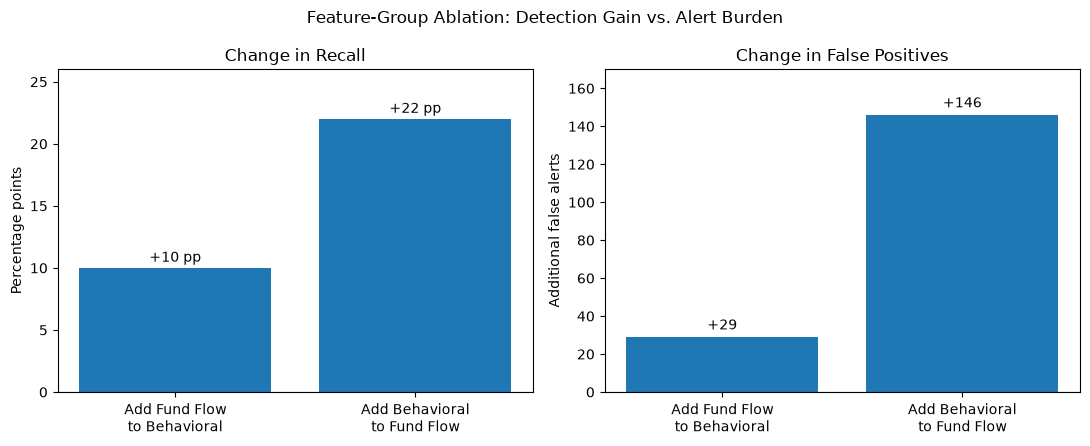

In [90]:

import matplotlib.pyplot as plt

plot_df = ablation_final_df.copy()

plot_labels = [
    "Add Fund Flow\nto Behavioral",
    "Add Behavioral\nto Fund Flow"
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Recall change in percentage points
axes[0].bar(
    plot_labels,
    plot_df["delta_recall"] * 100
)
axes[0].set_title("Change in Recall")
axes[0].set_ylabel("Percentage points")
axes[0].axhline(0, linewidth=0.8)
axes[0].set_ylim(0, 26)

for i, value in enumerate(plot_df["delta_recall"] * 100):
    axes[0].text(i, value + 0.5, f"+{value:.0f} pp",
                 ha="center")

# Additional false-positive alerts
axes[1].bar(
    plot_labels,
    plot_df["delta_FP"]
)
axes[1].set_title("Change in False Positives")
axes[1].set_ylabel("Additional false alerts")
axes[1].axhline(0, linewidth=0.8)
axes[1].set_ylim(0, 170)

for i, value in enumerate(plot_df["delta_FP"]):
    axes[1].text(i, value + 4, f"+{value}",
                 ha="center")

fig.suptitle(
    "Feature-Group Ablation: Detection Gain vs. Alert Burden"
)

plt.tight_layout()
plt.show()


## **Step 7.7 — Consistency Verification**

In [91]:

# Step 7.7 — Verify ablation consistency with V2 results

import numpy as np

models_to_check = [
    "behavioral",
    "fund_flow_core",
    "combined_core"
]

metrics_to_check = ["precision", "recall", "F1"]

for model_name in models_to_check:

    baseline_row = ablation_results.loc[model_name]
    count_row = ablation_counts.loc[model_name]

    tp = int(count_row["TP"])
    fp = int(count_row["FP"])
    fn = int(count_row["FN"])
    tn = int(count_row["TN"])
    alerts = int(count_row["alerts"])

    calculated = {
        "precision": tp / (tp + fp) if tp + fp else 0,
        "recall": tp / (tp + fn) if tp + fn else 0,
        "F1": 2 * tp / (2 * tp + fp + fn)
              if 2 * tp + fp + fn else 0
    }

    assert alerts == tp + fp
    assert tp + fp + fn + tn == 2000
    assert tp + fn == 100

    assert np.isclose(
        float(baseline_row["threshold"]),
        float(count_row["threshold"]),
        atol=1e-10,
        rtol=0
    ), f"Threshold mismatch: {model_name}"

    for metric in metrics_to_check:
        assert np.isclose(
            calculated[metric],
            float(baseline_row[metric]),
            atol=1e-4
        ), f"Metric mismatch: {model_name}, {metric}"

    print(f"{model_name}: PASS")

print("\nAll V2 ablation consistency checks passed.")


behavioral: PASS
fund_flow_core: PASS
combined_core: PASS

All V2 ablation consistency checks passed.


## **Step 8.1 — Inspect existing fusion implementation**


In [92]:


import inspect

for name in [
    "fusion_scores",
    "fusion_thresholds",
    "split_scores"
]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}:")
        print("Type:", type(obj).__name__)

        if isinstance(obj, dict):
            for key, value in obj.items():
                print(f"  {key}: {type(value).__name__}")
                if isinstance(value, dict):
                    print("    Keys:", list(value.keys()))

print("\nFusion-related functions:")
for name, obj in list(globals().items()):
    if callable(obj) and (
        "fusion" in name.lower()
        or "normaliz" in name.lower()
    ):
        print(name)



fusion_scores:
Type: dict
  behavioral: dict
    Keys: ['train', 'validation', 'test']
  fund_flow_core: dict
    Keys: ['train', 'validation', 'test']

fusion_thresholds:
Type: dict
  mean_fusion: float
  max_fusion: float

split_scores:
Type: dict
  train: ndarray
  validation: ndarray
  test: ndarray

Fusion-related functions:
confusion_matrix


In [93]:

# Step 8.2 — Find the original fusion implementation

from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw

keywords = [
    "mean_fusion",
    "max_fusion",
    "fusion_thresholds",
    "fusion_scores",
    "np.maximum",
    "np.mean"
]

for cell_number, source in enumerate(history):
    if any(keyword in source for keyword in keywords):
        if "Step 8.2" not in source:
            print(f"\n{'=' * 60}")
            print(f"Cell {cell_number}")
            print(source[:3500])



Cell 69

# Step 5.1 — Examine anomaly score distributions

import numpy as np
import pandas as pd

fusion_models = {
    "behavioral": model_behavioral,
    "fund_flow_core": model_fund_flow_core
}

fusion_scores = {}

for model_name, model in fusion_models.items():

    fusion_scores[model_name] = {}

    for split in ["train", "validation", "test"]:

        X = prepared_X[model_name][split]

        # Higher score = more anomalous
        scores = -model.score_samples(X)

        fusion_scores[model_name][split] = scores

# Summary based on Train scores only
score_summary = []

for model_name in fusion_models:

    scores = fusion_scores[model_name]["train"]

    score_summary.append({
        "model": model_name,
        "min": np.min(scores),
        "mean": np.mean(scores),
        "std": np.std(scores),
        "median": np.median(scores),
        "max": np.max(scores),
        "q95": np.quantile(scores, 0.95)
    })

score_summary_df = pd.DataFrame(score_summary)

display(scor